## 01 — Setup and Shared Storage

In [1]:
from pathlib import Path
import os, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
SEED = 42
# Optional shared storage: mount Drive for persistent files across Colab notebooks.
if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    ROOT = Path('/content/drive/MyDrive/CAI470_Project')
else:
    ROOT = Path.cwd() / 'CAI470_Project'
RAW = ROOT / 'raw'
OUT = ROOT / 'outputs'
FIG = OUT / 'figures'
for p in [RAW, OUT, FIG]: p.mkdir(parents=True, exist_ok=True)
print('Shared project folder:', ROOT)

Mounted at /content/drive
Shared project folder: /content/drive/MyDrive/CAI470_Project


## 02 — Load Model Results

In [2]:
comparison_path=OUT/'model_comparison.csv'; predictions_path=OUT/'test_predictions.csv'
assert comparison_path.exists() and predictions_path.exists(), 'Run Notebook 02 through Save Reusable Results using the same Google Drive folder.'
results=pd.read_csv(comparison_path)
preds=pd.read_csv(predictions_path)
assert len(results)==4 and len(preds)==82332
assert {'actual','attack_cat','id'}.issubset(preds.columns)
display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,FP,FN,TP,TN,Fit seconds
0,HistGradientBoosting,0.8729,0.8210,0.9835,0.8950,0.9855,0.9895,9719,747,44585,27281,12.68
1,Random Forest,0.8652,0.8086,0.9893,0.8899,0.9823,0.9868,10616,483,44849,26384,115.32
2,Decision Tree,0.8680,0.8269,0.9615,0.8891,0.9106,0.8806,9125,1746,43586,27875,13.33
3,Logistic Regression,0.8355,0.8022,0.9306,0.8617,0.9560,0.9666,10400,3145,42187,26600,16.03


## 03 — Recheck Class Distribution

In [3]:
print(preds['actual'].value_counts().rename({0:'Normal',1:'Attack'}))
print('Positive class: Attack = 1')

actual
Attack    45332
Normal    37000
Name: count, dtype: int64
Positive class: Attack = 1


## 04 — Compare Four Algorithms

,Model,Accuracy,Precision,Recall,F1-score,FP,FN
0,HistGradientBoosting,0.8729,0.8210,0.9835,0.8950,9719,747
1,Random Forest,0.8652,0.8086,0.9893,0.8899,10616,483
2,Decision Tree,0.8680,0.8269,0.9615,0.8891,9125,1746
3,Logistic Regression,0.8355,0.8022,0.9306,0.8617,10400,3145


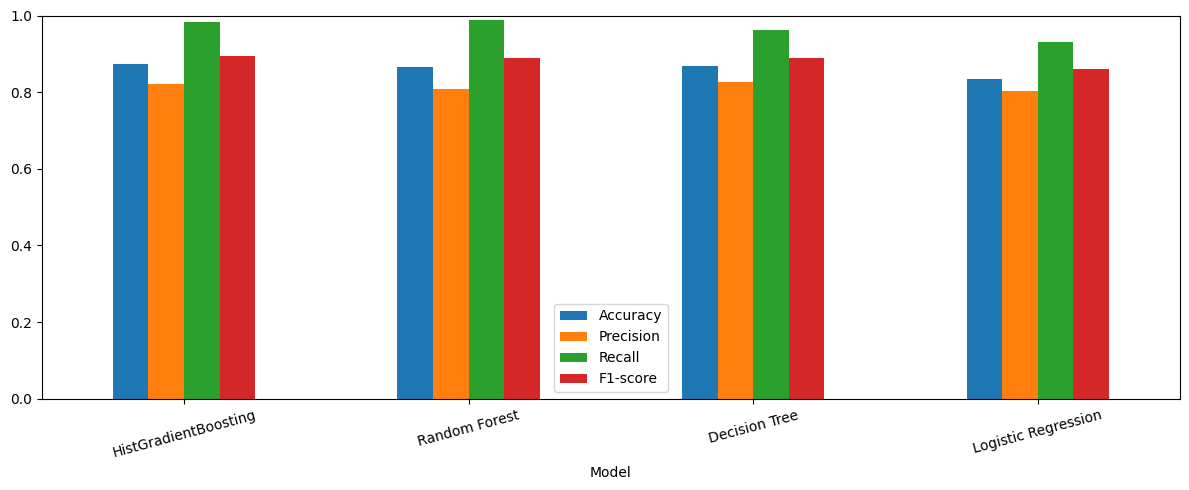

In [4]:
cols=['Model','Accuracy','Precision','Recall','F1-score','FP','FN']
display(results[cols].sort_values('F1-score',ascending=False).round(4))
results.set_index('Model')[['Accuracy','Precision','Recall','F1-score']].plot.bar(figsize=(12,5),ylim=(0,1),rot=15)
plt.tight_layout();plt.savefig(FIG/'final_model_comparison.png',dpi=150);plt.show()

## 05 — Confusion Matrices

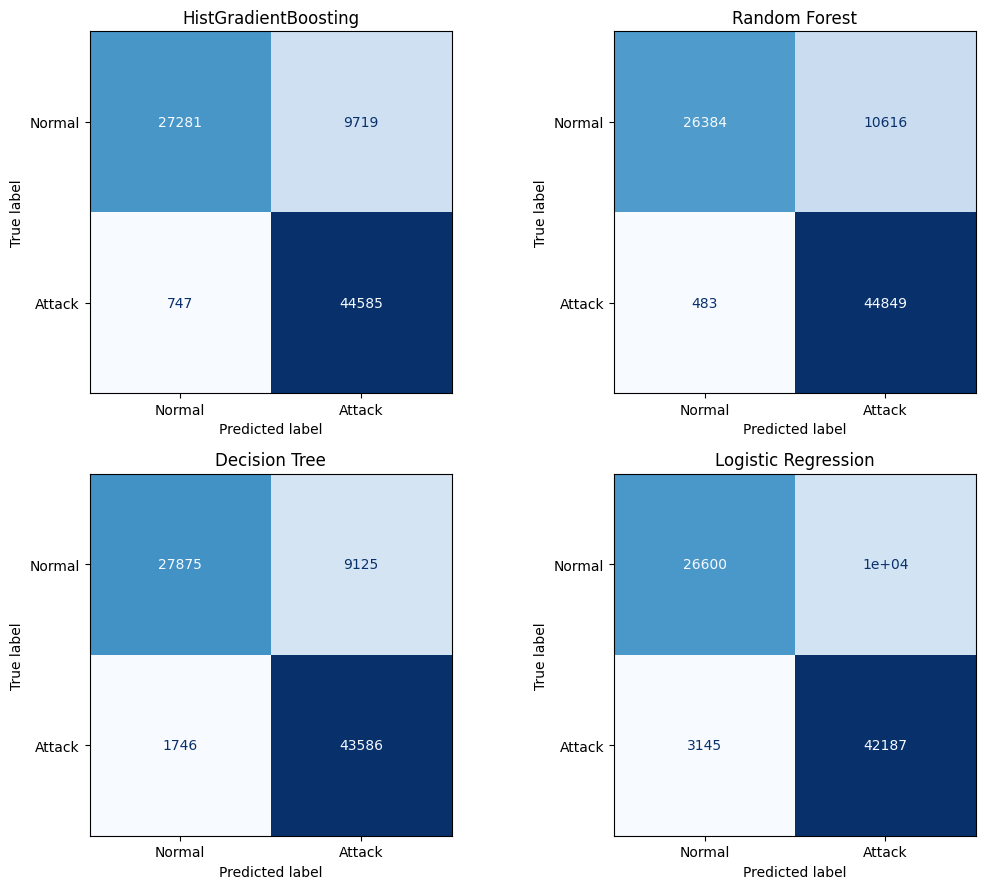

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig,axes=plt.subplots(2,2,figsize=(11,9))
for ax,name in zip(axes.flat,results.Model):
    tag=name.lower().replace(' ','_'); col=tag+'_prediction'
    assert col in preds
    cm=confusion_matrix(preds.actual,preds[col],labels=[0,1])
    ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=['Normal','Attack']).plot(ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(name)
plt.tight_layout();plt.savefig(FIG/'final_confusion_matrices.png',dpi=150);plt.show()

## 06 — False Positives and False Negatives

In [6]:
error_rows=[]
for name in results.Model:
    tag=name.lower().replace(' ','_')
    p=preds[tag+'_prediction'].astype(int);y=preds.actual.astype(int)
    error_rows.append({'Model':name,'False Positives':int(((y==0)&(p==1)).sum()),'False Negatives':int(((y==1)&(p==0)).sum()),'Attack Recall':float((p[y==1]==1).mean())})
error_df=pd.DataFrame(error_rows).sort_values('False Negatives')
display(error_df)
error_df.to_csv(OUT/'security_errors.csv',index=False)

,Model,False Positives,False Negatives,Attack Recall
1,Random Forest,10616,483,0.989345
0,HistGradientBoosting,9719,747,0.983522
2,Decision Tree,9125,1746,0.961484
3,Logistic Regression,10400,3145,0.930623


## 07 — Attack Category Detection

,Attack_Records,Detected,Missed,Attack_Recall
attack_cat,,,,
Fuzzers,6062,5400,662,0.890795
Analysis,677,654,23,0.966027
Shellcode,378,375,3,0.992063
Exploits,11132,11083,49,0.995598
Reconnaissance,3496,3490,6,0.998284
DoS,4089,4086,3,0.999266
Generic,18871,18870,1,0.999947
Backdoor,583,583,0,1.000000
Worms,44,44,0,1.000000


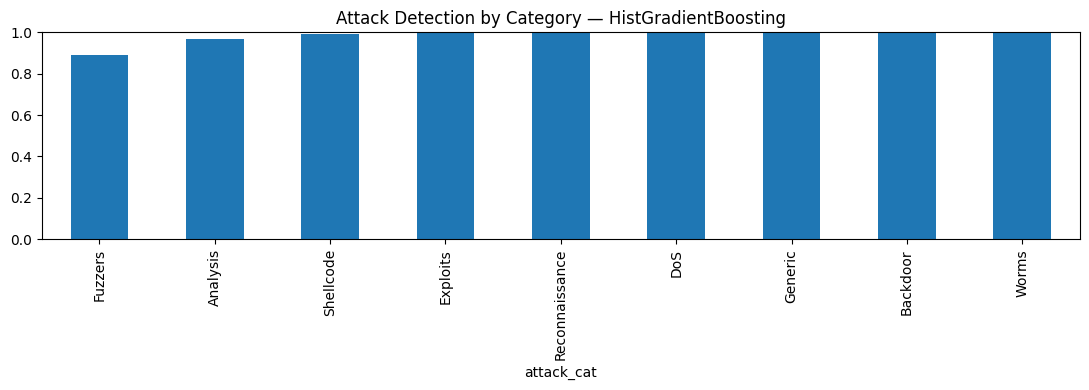

In [7]:
best_name=results.sort_values(['F1-score','Recall'],ascending=False).iloc[0].Model
pred_col=best_name.lower().replace(' ','_')+'_prediction'
attacks=preds[preds.actual==1].copy()
attack_stats=attacks.groupby('attack_cat').agg(Attack_Records=('actual','size'),Detected=(pred_col,'sum'))
attack_stats['Missed']=attack_stats['Attack_Records']-attack_stats['Detected']
attack_stats['Attack_Recall']=attack_stats['Detected']/attack_stats['Attack_Records']
attack_stats=attack_stats.sort_values('Attack_Recall')
display(attack_stats)
attack_stats.to_csv(OUT/'attack_category_detection.csv')
attack_stats['Attack_Recall'].plot.bar(figsize=(11,4),ylim=(0,1),title=f'Attack Detection by Category — {best_name}')
plt.tight_layout();plt.savefig(FIG/'attack_category_detection.png',dpi=150);plt.show()

## 08 — Inspect Hardest Attack Categories

In [8]:
print('Most difficult categories (lowest detected proportion):')
display(attack_stats.head(4))
print('Easiest categories (highest detected proportion):')
display(attack_stats.tail(4))
print('Note: this is binary attack detection broken down by known categories, NOT multiclass prediction.')

Most difficult categories (lowest detected proportion):


,Attack_Records,Detected,Missed,Attack_Recall
attack_cat,,,,
Fuzzers,6062,5400,662,0.890795
Analysis,677,654,23,0.966027
Shellcode,378,375,3,0.992063
Exploits,11132,11083,49,0.995598


Easiest categories (highest detected proportion):


,Attack_Records,Detected,Missed,Attack_Recall
attack_cat,,,,
DoS,4089,4086,3,0.999266
Generic,18871,18870,1,0.999947
Backdoor,583,583,0,1.000000
Worms,44,44,0,1.000000


Note: this is binary attack detection broken down by known categories, NOT multiclass prediction.


## 09 — Explainability Results

In [ ]:
imp_path=OUT/'best_model_permutation_importance.csv'
if imp_path.is_file():
    imp=pd.read_csv(imp_path)
    display(imp.head(15))
    imp.head(12).sort_values('Mean F1 decrease').plot.barh(x='Feature',y='Mean F1 decrease',legend=False,figsize=(9,5),title='Permutation Importance — Training Subset')
    plt.tight_layout();plt.savefig(FIG/'final_feature_importance.png',dpi=150);plt.show()
else:
    print('Run Notebook 02 — Global Explainability to create the feature importance output.')

## 10 — Cybersecurity Impact Summary

In [9]:
best=results.sort_values(['F1-score','Recall'],ascending=False).iloc[0]
summary={
'Best model (test F1)':best.Model,
'Test Accuracy':float(best.Accuracy),
'Test Precision':float(best.Precision),
'Test Attack Recall':float(best.Recall),
'Test F1':float(best['F1-score']),
'False Positives':int(best.FP),
'False Negatives':int(best.FN),
'Hardest Attack Category':str(attack_stats.index[0]),
'Limitation':'Fixed laboratory dataset, possible duplicate signatures across splits, class imbalance, limited generalization evidence'
}
print(json.dumps(summary,indent=2))
(OUT/'cybersecurity_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
print('False negatives are malicious flows classified as normal; they may allow attacks to go undetected.')
print('False positives can burden analysts and disrupt legitimate workflows.')

{
  "Best model (test F1)": "HistGradientBoosting",
  "Test Accuracy": 0.8728805324782588,
  "Test Precision": 0.8210260754272245,
  "Test Attack Recall": 0.983521574163946,
  "Test F1": 0.8949576458308242,
  "False Positives": 9719,
  "False Negatives": 747,
  "Hardest Attack Category": "Fuzzers",
  "Limitation": "Fixed laboratory dataset, possible duplicate signatures across splits, class imbalance, limited generalization evidence"
}
False negatives are malicious flows classified as normal; they may allow attacks to go undetected.
False positives can burden analysts and disrupt legitimate workflows.


## 11 — Final Submission Files

In [10]:
required=['model_comparison.csv','test_predictions.csv','security_errors.csv','attack_category_detection.csv','cybersecurity_summary.json','best_model_permutation_importance.csv']
for name in required:
    p=OUT/name
    print(('OK ' if p.exists() else 'MISSING ')+str(p))
print('Raw train/test CSV files live in:',RAW)
print('Written PDF report is required separately by the project instructions.')

OK /content/drive/MyDrive/CAI470_Project/outputs/model_comparison.csv
OK /content/drive/MyDrive/CAI470_Project/outputs/test_predictions.csv
OK /content/drive/MyDrive/CAI470_Project/outputs/security_errors.csv
OK /content/drive/MyDrive/CAI470_Project/outputs/attack_category_detection.csv
OK /content/drive/MyDrive/CAI470_Project/outputs/cybersecurity_summary.json
OK /content/drive/MyDrive/CAI470_Project/outputs/best_model_permutation_importance.csv
Raw train/test CSV files live in: /content/drive/MyDrive/CAI470_Project/raw
Written PDF report is required separately by the project instructions.
